# 05 · Vulnerabilidad: motorización y renta
**Pregunta:** ¿el impacto de las incidencias de Rodalies en los viajes a Barcelona es distinto según los coches y la renta de cada municipio?

- **Hipótesis de la motorización:** más coches → menos caída (la gente se pasa al coche).
- **Hipótesis de la renta:** menos renta → menos caída (no pueden teletrabajar ni dejar de ir).

In [1]:
from pathlib import Path
import numpy as np, pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
RAW = ROOT / "data" / "raw" / "socioeco"
PROC = ROOT / "data" / "processed" / "rmove"
print(ROOT)

C:\Users\marti\R-MOVE


## 1. Coches por municipio (DGT, 2023–2025)
Excel de la DGT con todos los municipios de España. Nos quedamos con la provincia de Barcelona (código INE que empieza por `08`) y con el parque de turismos y el censo de conductores.

In [2]:
dgt = []
for y in [2023, 2024, 2025]:
    d = pd.read_excel(RAW / f"dgt_municipal_{y}.xlsx", dtype={"Código INE": str})
    d = d[d["Código INE"].str[:2] == "08"].assign(anio=y)
    dgt.append(d[["Código INE", "anio", "Parque Turismos", "Censo Conductores"]])

dgt = pd.concat(dgt).rename(columns={"Código INE": "cod", "Parque Turismos": "turismos",
                                     "Censo Conductores": "conductores"})
print(dgt.shape)
dgt.head()

(936, 4)


,cod,anio,turismos,conductores
875,08000,2023,90.0,81.0
876,08001,2023,7337.0,8419.0
877,08002,2023,8819.0,179.0
878,08003,2023,5216.0,6588.0
879,08004,2023,157.0,179.0


## 2. Población (INE, Padrón 2023–2025)
Sirve de denominador para calcular la motorización (turismos por 1.000 habitantes). El CSV del INE viene en `latin-1` y usa el punto como separador de miles.

In [3]:
pad = pd.read_csv(RAW / "padron_08.csv", sep=";", dtype=str, encoding="latin-1")
pad = pad.assign(
    cod=pad.Municipios.str[:5],
    anio=pad.Periodo.astype(int),
    pob=pad.Total.str.replace(".", "", regex=False).astype(float),
)[["cod", "anio", "pob"]]

dgt = dgt.merge(pad, on=["cod", "anio"], how="left")
dgt["tur_1000"] = dgt.turismos / dgt.pob * 1000

print("Sin población:", dgt[dgt.pob.isna()].cod.unique())
dgt.head()

Sin población: <ArrowStringArray>
['08000']
Length: 1, dtype: str


,cod,anio,turismos,conductores,pob,tur_1000
0,08000,2023,90.0,81.0,NaN,NaN
1,08001,2023,7337.0,8419.0,12848.0,571.061644
2,08002,2023,8819.0,179.0,294.0,29996.598639
3,08003,2023,5216.0,6588.0,10139.0,514.449157
4,08004,2023,157.0,179.0,273.0,575.091575


In [4]:
tur_anio = dgt.pivot(index="cod", columns="anio", values="tur_1000").drop(index="08000", errors="ignore")

print("Correlación de Spearman entre años:")
display(tur_anio.corr("spearman").round(3))

print("\nMediana por año:")
print(tur_anio.median().round(1))

print("\nMotorización extrema (flotas de empresa registradas en pueblos pequeños):")
display(tur_anio.mean(axis=1).nlargest(5).round(0))

Correlación de Spearman entre años:


anio,2023,2024,2025
anio,,,
2023,1.000,0.983,0.976
2024,0.983,1.000,0.987
2025,0.976,0.987,1.000



Mediana por año:
anio
2023    562.0
2024    557.9
2025    568.0
dtype: float64

Motorización extrema (flotas de empresa registradas en pueblos pequeños):


cod
08002    28766.0
08178    13483.0
08027     2892.0
08277     2791.0
08177     1147.0
dtype: float64

**Lectura:** la motorización es muy estable entre 2023, 2024 y 2025 (Spearman ≈ 0,99), así que se usa un único valor por municipio: la media de los tres años. Hay valores extremos por flotas de renting registradas en pueblos pequeños, pero no forman parte de la muestra del análisis por municipios.

## 3. Renta y estructura de los hogares (INE, ADRH 2023–2024)
El fichero mezcla municipios, distritos y secciones censales. Nos quedamos con las filas de municipio (`Distritos` y `Secciones` vacías) y con la media de 2023 y 2024 (2025 aún no está publicado).
- **Renta:** renta neta media por persona y por hogar.
- **Demografía:** tamaño medio del hogar (para pasar a coches por hogar), % de 65 años o más y % de hogares unipersonales.

In [5]:
def leer_adrh(fichero, col_indicador, anios=("2023", "2024")):
    d = pd.read_csv(RAW / fichero, sep=";", dtype=str, encoding="utf-8-sig")
    d = d[d.Distritos.isna() & d.Secciones.isna() & d.Periodo.isin(anios)]   # solo municipios
    d = d.assign(
        cod=d.Municipios.str[:5],
        v=pd.to_numeric(d.Total.str.replace(".", "", regex=False)
                               .str.replace(",", ".", regex=False), errors="coerce"),
    )
    return d.pivot_table(index="cod", columns=col_indicador, values="v", aggfunc="mean")

ren = leer_adrh("adrh_renta_08.csv", "Indicadores de renta media y mediana")
dem = leer_adrh("adrh_demo_08.csv", "Indicadores demográficos")

print("Renta:", ren.shape, "| Demografía:", dem.shape)
print("\nIndicadores de renta:", list(ren.columns))
print("Indicadores demográficos:", list(dem.columns))

Renta: (307, 6) | Demografía: (311, 7)

Indicadores de renta: ['Media de la renta por unidad de consumo', 'Mediana de la renta por unidad de consumo', 'Renta bruta media por hogar', 'Renta bruta media por persona', 'Renta neta media por hogar', 'Renta neta media por persona']
Indicadores demográficos: ['Edad media de la población', 'Población', 'Porcentaje de hogares unipersonales', 'Porcentaje de población de 65 y más años', 'Porcentaje de población española', 'Porcentaje de población menor de 18 años', 'Tamaño medio del hogar']


In [6]:
display(ren[["Renta neta media por persona", "Renta neta media por hogar"]].describe().round(0))
display(dem[["Tamaño medio del hogar", "Porcentaje de población de 65 y más años"]].describe().round(2))

Indicadores de renta media y mediana,Renta neta media por persona,Renta neta media por hogar
count,307.0,307.0
mean,17532.0,46207.0
std,2350.0,8469.0
min,12851.0,31126.0
25%,16123.0,40580.0
50%,17104.0,44144.0
75%,18689.0,49330.0
max,27664.0,87949.0


Indicadores demográficos,Tamaño medio del hogar,Porcentaje de población de 65 y más años
count,311.00,311.00
mean,2.61,20.42
std,0.24,4.55
min,1.45,12.25
25%,2.50,17.30
50%,2.60,19.30
75%,2.75,22.33
max,3.40,43.20


## 4. Tabla socioeconómica por municipio
Un valor por municipio: la media de 2023–2025 para coches y población, y de 2023–2024 para la renta y la demografía.
- `tur_1000`: turismos por 1.000 habitantes (motorización).
- `cond_1000`: conductores con permiso por 1.000 habitantes.
- `tur_hogar`: turismos por hogar (aproximado = tur_1000 / 1000 × tamaño medio del hogar).

In [7]:
socio = (dgt[dgt.cod != "08000"]
         .groupby("cod")[["pob", "turismos", "conductores"]].mean())

socio["tur_1000"] = socio.turismos / socio.pob * 1000
socio["cond_1000"] = socio.conductores / socio.pob * 1000

socio = socio.join(
    ren[["Renta neta media por persona", "Renta neta media por hogar"]]
    .set_axis(["renta_pp", "renta_hogar"], axis=1)
)
socio = socio.join(
    dem[["Tamaño medio del hogar", "Porcentaje de población de 65 y más años", "Porcentaje de hogares unipersonales"]]
    .set_axis(["tam_hogar", "pct_65", "pct_unip"], axis=1)
)
socio["tur_hogar"] = socio.tur_1000 / 1000 * socio.tam_hogar

print(socio.shape)
print("Sin renta:", socio.renta_pp.isna().sum(), "municipios")
socio.head()

(311, 11)
Sin renta: 4 municipios


,pob,turismos,conductores,tur_1000,cond_1000,renta_pp,renta_hogar,tam_hogar,pct_65,pct_unip,tur_hogar
cod,,,,,,,,,,,
08001,13029.666667,7408.000000,8548.000000,568.548697,656.041342,17203.0,46348.5,2.7,17.00,19.90,1.535081
08002,292.333333,8410.666667,182.666667,28770.809578,624.857469,19459.5,54185.5,2.8,19.50,29.90,80.558267
08003,10206.000000,5205.666667,6666.000000,510.059442,653.145209,25577.0,72890.0,2.8,22.10,20.50,1.428166
08004,270.000000,157.333333,186.666667,582.716049,691.358025,20202.0,44441.0,2.2,21.05,35.90,1.281975
08005,9410.666667,5482.333333,6532.666667,582.565883,694.176821,22011.0,64717.5,2.9,16.20,16.85,1.689441


In [8]:
info = pd.read_parquet(PROC / "municipios_info.parquet")
X = info.join(socio)

print("Municipios analizados:", len(X))
print("Sin datos socioeconómicos:", X.tur_1000.isna().sum(), "| sin renta:", X.renta_pp.isna().sum())

display(X.groupby("grupo")[["tur_1000", "tur_hogar", "cond_1000", "renta_pp", "tam_hogar"]].median().round(1))

Municipios de M2: 133
Sin datos socioeconómicos: 0 | sin renta: 0


,tur_1000,tur_hogar,cond_1000,renta_pp,tam_hogar
grupo,,,,,
Cercano sin metro/FGC,469.6,1.2,590.8,17147.0,2.6
Con metro/FGC,386.5,1.0,540.6,15365.5,2.6
Dependiente,485.6,1.3,586.6,16859.5,2.6
Sin Rodalies (control),525.6,1.4,637.6,17551.0,2.7


**Lectura:** los municipios con metro/FGC tienen la menor motorización (≈ 390 turismos por 1.000 hab.) y la menor renta; los municipios sin Rodalies, la mayor (≈ 525). Donde el transporte público es mejor hacen falta menos coches. Por eso la motorización está mezclada con la alternativa de transporte, y habrá que controlarla en el modelo.

## 5. Impacto por municipio (método del clustering del notebook 03)
Para cada municipio *m* y día de caos *d*:

efecto = (V_m,d / mediana de V_m en los días limpios del mismo tipo y año) ÷ (lo mismo para la suma de los municipios sin Rodalies) − 1

Es el mismo efecto corregido por el control del notebook 03, pero calculado municipio a municipio.

In [9]:
V = pd.read_parquet(PROC / "municipios_panel_viajes.parquet")              # viajes diarios a BCN: días × municipios
cal = pd.read_parquet(PROC / "municipios_calendario.parquet")
tipo = pd.read_parquet(PROC / "municipios_tipos_dia.parquet").tipo
caos = pd.read_parquet(PROC / "municipios_dias_caos.parquet").fecha.tolist()
ctrl = pd.read_parquet(PROC / "municipios_control.parquet").municipio_code.tolist()

limpios = [d for d in V.index if cal.loc[d, "limpio"]]
V_ctrl = V[ctrl].sum(axis=1)

def efecto_dia(d):
    ref = [x for x in limpios if x.year == d.year and tipo[x] == tipo[d] and x != d]
    ratio_mun = V.loc[d] / V.loc[ref].median()
    ratio_ctrl = V_ctrl.loc[d] / V_ctrl.loc[ref].median()
    return (ratio_mun / ratio_ctrl - 1) * 100

E = pd.DataFrame({d.strftime("%Y-%m-%d"): efecto_dia(d) for d in caos})
E["media_caos"] = E.mean(axis=1)

print("Días de caos:", [d.strftime("%Y-%m-%d") for d in caos], "| tipos:", [tipo[d] for d in caos])
display(info[["grupo"]].join(E).groupby("grupo").median().round(1))

Días de caos: ['2024-05-13', '2025-03-17', '2025-03-26', '2025-04-01'] | tipos: ['A', 'B', 'B', 'B']


,2024-05-13,2025-03-17,2025-03-26,2025-04-01,media_caos
grupo,,,,,
Cercano sin metro/FGC,-2.2,-5.7,-4.0,-6.0,-4.5
Con metro/FGC,4.5,-1.5,-2.0,-1.1,-1.0
Dependiente,-10.9,-9.0,1.8,-5.9,-4.5
Sin Rodalies (control),-1.3,-1.3,2.2,-2.2,-0.4


**Lectura:** municipio a municipio se reproduce el patrón del análisis por municipios (notebook 03): los dependientes y los cercanos sin metro/FGC caen ≈ 4,5 % de media en los días de caos, los que tienen metro o FGC apenas cambian y el control queda en ≈ 0. El 26/03/2025 la mediana de los dependientes es positiva: el impacto de esa huelga fue muy desigual entre municipios.

## 6. Ruido de cada municipio (placebos)
Un municipio pequeño puede salir en −15 % solo por azar. Para medir ese ruido se repite el cálculo tratando cada día limpio como si fuera un día de caos (placebo, efecto real = 0). La variabilidad de la **media de 4 placebos al azar** da el error típico de `media_caos` en cada municipio.

En el modelo se usará como peso 1 / error²: los municipios más fiables pesan más.

*Simplificación:* a diferencia del notebook 03, aquí los placebos no reentrenan el clustering, así que el error puede estar algo infraestimado.

In [10]:
PL = pd.DataFrame({d: efecto_dia(d) for d in limpios})          # municipios × días limpios

rng = np.random.default_rng(0)
sims = np.array([PL.iloc[:, rng.choice(PL.shape[1], len(caos), replace=False)].mean(axis=1)
                 for _ in range(2000)])
E["sd_media"] = sims.std(axis=0)

X = info.join(E).join(socio)
print("Error típico de media_caos (pp) por grupo:")
display(X.groupby("grupo").sd_media.describe()[["min", "50%", "max"]].round(1))

# ¿Cuántos municipios con Rodalies caen más de lo que explicaría el azar?
rod = X[X.rodalies]
print("Municipios con Rodalies con caída > 2 errores típicos:",
      (rod.media_caos < -2 * rod.sd_media).sum(), "de", len(rod))

Error típico de media_caos (pp) por grupo:


,min,50%,max
grupo,,,
Cercano sin metro/FGC,2.0,3.4,9.9
Con metro/FGC,1.3,2.1,4.2
Dependiente,2.2,5.1,13.8
Sin Rodalies (control),1.6,5.4,19.6


Municipios con Rodalies con caída > 2 errores típicos: 17 de 62


**Lectura:** el error típico de `media_caos` va de ≈ 2 pp (municipios grandes, con metro/FGC) a más de 14 pp (municipios pequeños). 17 de los 62 municipios con Rodalies caen más de 2 errores típicos. Por eso el modelo pondera cada municipio por 1 / error².

## 7. Exploración
Primero, sin controlar nada: ¿los municipios con más coches o más renta caen menos? Muestra: los 62 municipios con Rodalies.

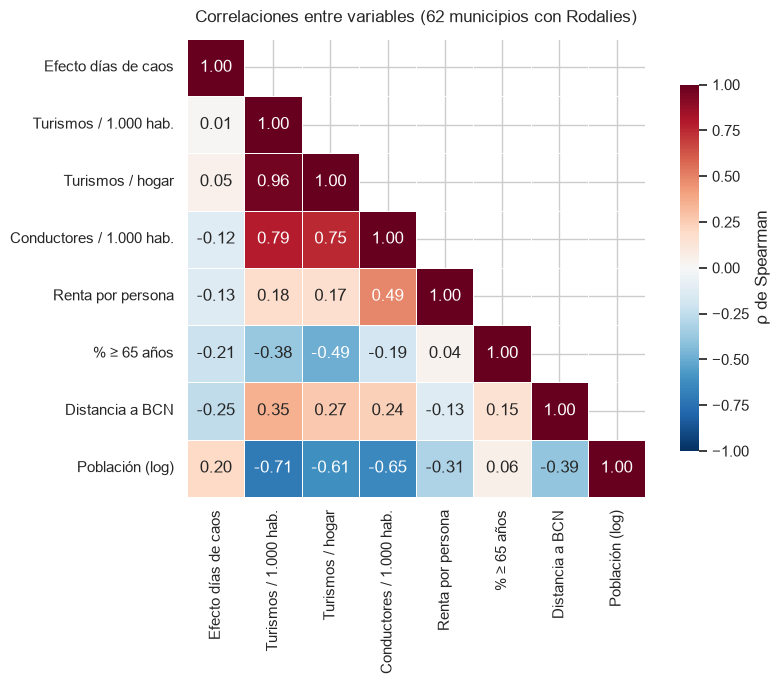

In [11]:
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import spearmanr
sns.set_theme(style="whitegrid")

rod = X[X.rodalies].copy()
rod["log_pob"] = np.log(rod.pob)

etiquetas = {
    "media_caos": "Efecto días de caos",
    "tur_1000": "Turismos / 1.000 hab.",
    "tur_hogar": "Turismos / hogar",
    "cond_1000": "Conductores / 1.000 hab.",
    "renta_pp": "Renta por persona",
    "pct_65": "% ≥ 65 años",
    "dist_km": "Distancia a BCN",
    "log_pob": "Población (log)",
}
corr = rod[list(etiquetas)].corr("spearman").rename(index=etiquetas, columns=etiquetas)

mask = np.triu(np.ones_like(corr, dtype=bool), k=1)   # oculta el triángulo superior (repetido)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            center=0, square=True, linewidths=.5, cbar_kws={"shrink": .8, "label": "ρ de Spearman"}, ax=ax)
ax.set_title("Correlaciones entre variables (62 municipios con Rodalies)", pad=12)
plt.tight_layout(); plt.show()

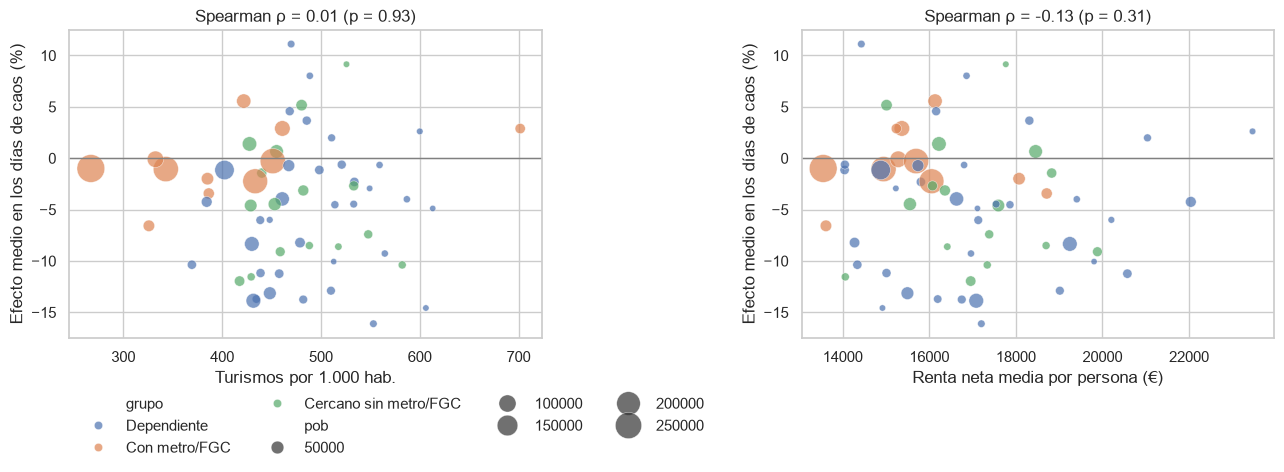

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, v, lab in [(ax[0], "tur_1000", "Turismos por 1.000 hab."),
                  (ax[1], "renta_pp", "Renta neta media por persona (€)")]:
    sns.scatterplot(data=rod, x=v, y="media_caos", hue="grupo", size="pob",
                    sizes=(20, 400), alpha=.7, ax=a)
    a.axhline(0, c="grey", lw=1)
    a.set_xlabel(lab); a.set_ylabel("Efecto medio en los días de caos (%)")
    r = spearmanr(rod[v], rod.media_caos)
    a.set_title(f"Spearman ρ = {r.statistic:.2f} (p = {r.pvalue:.2f})")
ax[1].get_legend().remove()
ax[0].legend(bbox_to_anchor=(0, -0.15), loc="upper left", ncol=4, frameon=False)
plt.tight_layout(); plt.show()

**Lectura:** sin controles no hay relación entre el efecto y la motorización (ρ = 0,02) ni con la renta (ρ = −0,13). Pero la motorización está muy ligada al tamaño del municipio (ρ = −0,71) y a la distancia (ρ = 0,35), que a su vez influyen en el efecto. Los municipios con metro/FGC son grandes, tienen pocos coches y apenas caen. Para aislar el papel de los coches y la renta hay que comparar municipios a igual distancia y con la misma alternativa → regresión con controles.

## 8. Regresión ponderada con controles
efecto medio ~ motorización + renta + distancia + metro/FGC

- Pesos: 1 / error² (paso 6).
- Errores robustos (HC1).
- Escalas: `tur100` = +100 turismos por 1.000 hab.; `renta_k` = +1.000 € por persona; `dist10` = +10 km.
- Coeficiente **positivo** = **menos caída**.

In [13]:
import statsmodels.formula.api as smf

rod["con_alt"] = rod.con_alt.astype(int)
rod["w"] = 1 / rod.sd_media**2
rod["tur100"] = rod.tur_1000 / 100
rod["renta_k"] = rod.renta_pp / 1000
rod["dist10"] = rod.dist_km / 10

formulas = {
    "Motorización + renta": "media_caos ~ tur100 + renta_k + dist10 + con_alt",
    "Solo motorización":    "media_caos ~ tur100 + dist10 + con_alt",
    "Solo renta":           "media_caos ~ renta_k + dist10 + con_alt",
}
filas = []
for nombre, f in formulas.items():
    m = smf.wls(f, data=rod, weights=rod.w).fit(cov_type="HC1")
    ic = m.conf_int()
    for v in m.params.index.drop("Intercept"):
        filas.append({"modelo": nombre, "variable": v, "coef_pp": m.params[v],
                      "IC95": f"[{ic.loc[v,0]:+.1f}, {ic.loc[v,1]:+.1f}]", "p": m.pvalues[v], "R2": m.rsquared})
res = pd.DataFrame(filas)
display(res.round(3))

,modelo,variable,coef_pp,IC95,p,R2
0,Motorización + renta,tur100,1.397,"[+0.4, +2.4]",0.008,0.218
1,Motorización + renta,renta_k,-0.380,"[-1.0, +0.2]",0.233,0.218
2,Motorización + renta,dist10,-0.894,"[-2.0, +0.2]",0.105,0.218
3,Motorización + renta,con_alt,3.115,"[+0.8, +5.4]",0.008,0.218
4,Solo motorización,tur100,1.112,"[+0.0, +2.2]",0.042,0.198
5,Solo motorización,dist10,-0.776,"[-1.8, +0.3]",0.148,0.198
6,Solo motorización,con_alt,3.602,"[+1.4, +5.8]",0.002,0.198
7,Solo renta,renta_k,-0.234,"[-0.9, +0.4]",0.462,0.181
8,Solo renta,dist10,-0.592,"[-1.6, +0.4]",0.261,0.181
9,Solo renta,con_alt,2.474,"[+0.2, +4.7]",0.029,0.181


**Lectura:** comparando municipios a igual distancia y con la misma alternativa:
- **Motorización:** +100 turismos por 1.000 hab. → **1,4 pp menos de caída** (IC95 [+0,4, +2,4], p = 0,006). Pasar de 400 a 600 turismos por 1.000 hab. supone ≈ 3 pp menos de caída. Apoya la hipótesis de la motorización.
- **Renta:** sin efecto significativo (−0,4 pp por +1.000 €, p = 0,22). La hipótesis de la renta no se sostiene.
- **Metro/FGC:** ≈ +3 pp (p = 0,008): la alternativa sigue siendo lo que más pesa.
- R² ≈ 0,22: la socioeconomía explica una parte modesta de las diferencias entre municipios.

## 9. Robustez del efecto de la motorización
a) Quitar un municipio cada vez. b) Test de permutación (reasignar la motorización al azar). c) Sin pesos. d) Placebo en los municipios sin Rodalies (no debería salir nada).

In [14]:
f = "media_caos ~ tur100 + renta_k + dist10 + con_alt"
b0 = smf.wls(f, data=rod, weights=rod.w).fit().params.tur100

# a) Quitar un municipio cada vez
loo = pd.Series({i: smf.wls(f, data=rod.drop(i), weights=rod.drop(i).w).fit().params.tur100 for i in rod.index})
print(f"a) Coef. = {b0:.2f} · quitando un municipio: [{loo.min():.2f}, {loo.max():.2f}]"
      f" · el que más influye: {rod.loc[(loo - b0).abs().idxmax(), 'municipio']}")

# b) Permutación
rng = np.random.default_rng(1)
perm = [smf.wls(f, data=rod.assign(tur100=rng.permutation(rod.tur100.values)), weights=rod.w).fit().params.tur100
        for _ in range(2000)]
print(f"b) p por permutación: {np.mean(np.abs(perm) >= abs(b0)):.3f}")

# c) Sin pesos
m = m_sin_pesos = smf.ols(f, data=rod).fit(cov_type="HC1")
print(f"c) Sin pesos: coef = {m.params.tur100:.2f}, p = {m.pvalues.tur100:.3f}")

# d) Placebo: municipios sin Rodalies
c = X[~X.rodalies].assign(w=lambda d: 1 / d.sd_media**2, tur100=lambda d: d.tur_1000 / 100, renta_k=lambda d: d.renta_pp / 1000)
m = m_placebo = smf.wls("media_caos ~ tur100 + renta_k", data=c, weights=c.w).fit(cov_type="HC1")
print(f"d) Control sin Rodalies: motorización p = {m.pvalues.tur100:.2f}, renta p = {m.pvalues.renta_k:.2f}")

a) Coef. = 1.40 · quitando un municipio: [1.20, 1.60] · el que más influye: Castellbisbal


b) p por permutación: 0.048
c) Sin pesos: coef = 1.35, p = 0.109
d) Control sin Rodalies: motorización p = 0.69, renta p = 0.21


**Lectura:** el efecto de la motorización es robusto a quitar cualquier municipio (coef. entre 1,24 y 1,61) y al test de permutación (p = 0,04), y en el control sin Rodalies no aparece ninguna relación (p = 0,74). Sin pesos el coeficiente es parecido (1,36) pero deja de ser significativo (p = 0,10): la evidencia es **moderada** y depende de dar más peso a los municipios con menos ruido.

## 10. Día a día y control por transporte alternativo
- ¿El patrón se repite en cada día de caos, o lo produce uno solo?
- ¿Se mantiene si se controla también por la conectividad en transporte alternativo (bus interurbano, AMB, FGC), la misma que usa el dashboard?

In [15]:
dias = [d.strftime("%Y-%m-%d") for d in caos]
filas = []
for d in dias:
    m = smf.ols(f"Q('{d}') ~ tur100 + renta_k + dist10 + con_alt", data=rod).fit(cov_type="HC1")
    filas.append({"día": d, "coef_motorización": m.params.tur100, "p_motorización": m.pvalues.tur100,
                  "coef_renta": m.params.renta_k, "p_renta": m.pvalues.renta_k})
display(pd.DataFrame(filas).round(3))

,día,coef_motorización,p_motorización,coef_renta,p_renta
0,2024-05-13,2.334,0.295,-1.500,0.007
1,2025-03-17,0.559,0.754,-0.304,0.687
2,2025-03-26,1.203,0.383,0.692,0.340
3,2025-04-01,1.314,0.325,0.316,0.583


In [16]:
con = pd.read_parquet(PROC / "conectividad_municipios.parquet")[["sin_alt_directa", "penalizacion", "alternativa"]]
rod = rod.drop(columns=con.columns, errors="ignore").join(con)
rod["sin_alt"] = rod.sin_alt_directa.astype(int)

m_transporte = {}
for nombre, f, datos in [
    ("+ sin alternativa directa", "media_caos ~ tur100 + renta_k + dist10 + con_alt + sin_alt", rod),
    ("+ penalización de tiempo (10 min)", "media_caos ~ tur100 + renta_k + dist10 + con_alt + I(penalizacion/10)",
     rod.dropna(subset=["penalizacion"])),
]:
    m = smf.wls(f, data=datos, weights=datos.w).fit(cov_type="HC1")
    m_transporte[nombre] = m
    extra = m.params.index[-1]
    print(f"{nombre} (n={int(m.nobs)}): motorización {m.params.tur100:.2f} (p={m.pvalues.tur100:.3f}) · "
          f"{extra} {m.params[extra]:.2f} (p={m.pvalues[extra]:.2f})")

+ sin alternativa directa (n=62): motorización 1.38 (p=0.011) · sin_alt -1.86 (p=0.41)
+ penalización de tiempo (10 min) (n=46): motorización 1.40 (p=0.016) · I(penalizacion / 10) -0.29 (p=0.49)


**Lectura:**
- La motorización tiene signo positivo los 4 días (de +0,6 a +2,4), pero ninguno es significativo por sí solo: el efecto solo se detecta al promediar los días de caos.
- **Renta, solo en la avería sin aviso (13/05/2024):** los municipios con más renta cayeron más (−1,6 pp por cada +1.000 €, p = 0,004), lo que es coherente con poder teletrabajar o cancelar ante un imprevisto. En las huelgas anunciadas no aparece. Es un único resultado entre 8 pruebas: se plantea como hipótesis.
- Controlando por el transporte alternativo (sin alternativa directa o penalización de tiempo), el efecto de la motorización no cambia (≈ +1,4, p < 0,02). El bus no añade explicación una vez se tiene en cuenta el metro/FGC.

## 11. Lectura sencilla: dependientes por terciles
Los municipios dependientes (≥ 20 km, sin metro/FGC) ya son comparables entre sí. Se dividen en tres grupos iguales según la motorización y la renta.

In [17]:
dep = rod[rod.grupo == "Dependiente"].copy()
dep["terc_motor"] = pd.qcut(dep.tur_1000, 3, labels=["baja", "media", "alta"])
dep["terc_renta"] = pd.qcut(dep.renta_pp, 3, labels=["baja", "media", "alta"])

for c, nombre in [("terc_motor", "Motorización"), ("terc_renta", "Renta")]:
    t = dep.groupby(c, observed=True).apply(lambda d: pd.Series({
        "municipios": len(d),
        "rango": f"{d[c.replace('terc_motor','tur_1000').replace('terc_renta','renta_pp')].min():.0f}–{d[c.replace('terc_motor','tur_1000').replace('terc_renta','renta_pp')].max():.0f}",
        "efecto_ponderado_%": round(np.average(d.media_caos, weights=d.w), 1),
    }))
    print(nombre); display(t)

Motorización


,municipios,rango,efecto_ponderado_%
terc_motor,,,
baja,12,369–461,-7.1
media,11,467–513,-1.9
alta,12,514–613,-3.9


Renta


,municipios,rango,efecto_ponderado_%
terc_renta,,,
baja,12,14042–15805,-3.6
media,11,16157–17202,-6.6
alta,12,17544–23467,-5.9


## 12. Conclusiones
1. **Motorización, evidencia moderada:** a igual distancia y alternativa, +100 turismos por 1.000 hab. → 1,4 pp menos de caída (p = 0,006; permutación p = 0,04). Robusto a quitar municipios y a controlar por el transporte alternativo; mismo signo los 4 días. Sin pesos deja de ser significativo (p = 0,10).
2. **Renta, sin efecto en conjunto.** Solo en la avería sin aviso los municipios con más renta cayeron más (hipótesis: teletrabajo o cancelación).
3. **Lo que más pesa sigue siendo tener metro/FGC** (≈ +3 pp).
4. **Limitaciones:** 62 municipios y 4 días de caos (poca potencia); asociación, no causalidad; turismos de empresa registrados en algunos municipios; sin datos de la cuota de tren de cada municipio.

In [18]:
import json
OBS = PROC / "observatorio"; OBS.mkdir(exist_ok=True)

# Niveles con los cortes de los terciles de los dependientes
corte = lambda col: [dep[col][pd.qcut(dep[col], 3, labels=False) == k].max() for k in (0, 1)]
cm, cr = corte("tur_1000"), corte("renta_pp")
nivel = lambda v, c: None if pd.isna(v) else ("baja" if v <= c[0] else "media" if v <= c[1] else "alta")

vuln = {cod: {"motorizacion": round(r.tur_1000), "renta": None if pd.isna(r.renta_pp) else round(r.renta_pp),
              "turismos_hogar": round(r.tur_hogar, 2), "conductores": round(r.cond_1000),
              "nivel_motorizacion": nivel(r.tur_1000, cm), "nivel_renta": nivel(r.renta_pp, cr)}
        for cod, r in X.dropna(subset=["tur_1000"]).iterrows()}

def terciles(col):
    out = []
    for niv, d in dep.groupby(pd.qcut(dep[col], 3, labels=["baja", "media", "alta"]), observed=True):
        mu, se = np.average(d.media_caos, weights=d.w), np.sqrt(1 / d.w.sum())
        out.append({"nivel": str(niv), "municipios": len(d), "min": round(d[col].min()), "max": round(d[col].max()),
                    "efecto": round(mu, 2), "ic_inf": round(mu - 1.96 * se, 2), "ic_sup": round(mu + 1.96 * se, 2)})
    return out

mod = smf.wls(f, data=rod, weights=rod.w).fit(cov_type="HC1"); ic = mod.conf_int()
etq = {"tur100": "+100 turismos por 1.000 hab.", "renta_k": "+1.000 € de renta por persona",
       "dist10": "+10 km de distancia a Barcelona", "con_alt": "Tener metro o FGC"}
resumen = {
    "fuente": "DGT (2023–2025), INE Padrón (2023–2025) e INE ADRH (2023–2024). Efecto: clustering del notebook 03 por municipio. Notebook 05.",
    "muestra": len(rod), "dependientes": len(dep),
    "mediana_motorizacion": round(rod.tur_1000.median()), "mediana_renta": round(rod.renta_pp.median()),
    "cortes_motorizacion": [round(x) for x in cm], "cortes_renta": [round(x) for x in cr],
    "modelo": [{"variable": v, "etiqueta": e, "coef_pp": round(mod.params[v], 2), "ic_inf": round(ic.loc[v, 0], 2),
                "ic_sup": round(ic.loc[v, 1], 2), "p": round(mod.pvalues[v], 4)} for v, e in etq.items()],
    "r2": round(mod.rsquared, 2),
    "robustez": {   # cifras de las celdas de robustez (pasos 9 y 10)
        "quitar_un_municipio": [round(loo.min(), 2), round(loo.max(), 2)],
        "p_permutacion": round(float(np.mean(np.abs(perm) >= abs(b0))), 3),
        "sin_pesos": {"coef_pp": round(m_sin_pesos.params.tur100, 2), "p": round(m_sin_pesos.pvalues.tur100, 3)},
        "control_transporte_alternativo": {"coef_pp": round(m_transporte["+ sin alternativa directa"].params.tur100, 2),
                                           "p": round(m_transporte["+ sin alternativa directa"].pvalues.tur100, 3)},
        "placebo_sin_rodalies": {"p_motorizacion": round(m_placebo.pvalues.tur100, 2), "p_renta": round(m_placebo.pvalues.renta_k, 2)}},
    "por_dia": [{"fecha": x["día"], "coef_motorizacion": round(x["coef_motorización"], 2), "p_motorizacion": round(x["p_motorización"], 3),
                 "coef_renta": round(x["coef_renta"], 2), "p_renta": round(x["p_renta"], 3)} for x in filas if "día" in x],
    "terciles_motorizacion": terciles("tur_1000"), "terciles_renta": terciles("renta_pp"),
}
(OBS / "vulnerabilidad.json").write_text(json.dumps(vuln, ensure_ascii=False, indent=1), encoding="utf-8")
(OBS / "vulnerabilidad_resumen.json").write_text(json.dumps(resumen, ensure_ascii=False, indent=1), encoding="utf-8")
print("Exportado:", len(vuln), "municipios · ahora ejecuta: python src/dashboard-v2/build_observatorio.py")

Exportado: 133 municipios · ahora ejecuta: python src/dashboard-v2/build_observatorio.py


In [19]:
# El observatorio se regenera con: python scripts/actualizar_dashboard.py
# (o solo el JSON: python src/dashboard-v2/build_observatorio.py)
